# Proyek Analisis Data: Bike Sharing Dataset
- **Nama:** Rama Dwi Nugraha
- **Email:** iooloittrr@gmail.com
- **ID Dicoding:** rama_dwi_nugrahaoh17

---
## 1. Menentukan Pertanyaan Bisnis (SMART Framework)
Analisis data ini dirancang untuk menjawab 4 pertanyaan bisnis strategis dengan menerapkan kerangka **SMART** (*Specific, Measurable, Action-oriented, Relevant, Time-bound*):

1. **Pertanyaan 1 (Pengaruh Musim & Cuaca):**
   Bagaimana pengaruh kondisi musim (*Season*) dan kondisi cuaca (*Weather Situation*) terhadap rata-rata dan total volume penyewaan sepeda harian sepanjang periode 2011–2012?
   - **Specific:** Mengukur variasi performa rental pada masing-masing musim (Spring, Summer, Fall, Winter) dan situasi cuaca (Cerah/Sebagian Berawan, Berkabut/Mendung, Hujan Ringan/Salju).
   - **Measurable:** Dihitung dari metrik statistik rata-rata harian dan total sewa (`cnt`).
   - **Action-oriented:** Menentukan kebijakan pemeliharaan armada dan kesiapan stok unit di stasiun dok sepeda.
   - **Relevant:** Berdampak langsung terhadap keandalan operasional dan pengalaman pelanggan.
   - **Time-bound:** Periode 2 tahun kalender penuh (1 Januari 2011 – 31 Desember 2012).

2. **Pertanyaan 2 (Pola Jam & Tipe Hari):**
   Pada jam berapa saja terjadi lonjakan puncak (*peak rush hours*) penyewaan sepeda sepanjang tahun 2011–2012, dan bagaimana perbedaan pola perilakunya antara hari kerja (*Working Day*) dibandingkan hari libur/akhir pekan (*Weekend / Holiday*) pada periode yang sama?
   - **Specific:** Mengidentifikasi jam sibuk operasional persewaan dan membandingkan profil mobilitas harian antara komuter pekerja dengan rekreasi santai.
   - **Measurable:** Jumlah unit sepeda tersewa per jam (rentang 00:00 sampai 23:00) pada hari kerja dibandingkan hari libur.
   - **Action-oriented:** Mengatur jadwal redistribusi truk armada sebelum jam sibuk agar stasiun tidak kehabisan unit sepeda.
   - **Relevant:** Menjaga rasio utilisasi armada dan mencegah kekecewaan pelanggan akibat stasiun kosong.
   - **Time-bound:** Berdasarkan seluruh data per jam sepanjang tahun 2011–2012 (dua tahun penuh).

3. **Pertanyaan 3 (Tren Pertumbuhan Pengguna Casual vs Registered):**
   Bagaimana dinamika tren pertumbuhan bulanan dan proporsi kontribusi antara pengguna kasual (*Casual Users*) dan pengguna terdaftar (*Registered Members*) dari tahun 2011 hingga 2012?
   - **Specific:** Membedah proporsi kontribusi serta tren adopsi pengguna kasual versus pengguna terdaftar dari bulan ke bulan.
   - **Measurable:** Persentase kontribusi bulanan (%) dan volume total sewa kedua segmen pengguna.
   - **Action-oriented:** Merancang paket langganan musiman dan program promosi konversi pengguna kasual menjadi anggota terdaftar.
   - **Relevant:** Anggota terdaftar menjamin stabilitas pendapatan berulang (*recurring revenue*) bagi perusahaan.
   - **Time-bound:** Evaluasi bulanan dari Januari 2011 sampai Desember 2012 (24 bulan).

4. **Pertanyaan 4 (Advanced Analysis - Clustering & Binning Parameter Lingkungan):**
   Bagaimana segmentasi volume rental sepeda berdasarkan klaster rentang temperatur suhu (*Temperature Binning*) dan tingkat kelembapan (*Humidity Binning*) tanpa algoritma machine learning selama periode 2011–2012?
   - **Specific:** Mengelompokkan observasi suhu dan kelembapan ke dalam kategori intuitif (Suhu: Dingin, Sejuk, Hangat, Panas; Kelembapan: Kering, Nyaman/Ideal, Lembap).
   - **Measurable:** Rata-rata rental per jam pada setiap segmen kombinasi suhu dan kelembapan.
   - **Action-oriented:** Menyusun pedoman operasional dan notifikasi keselamatan cuaca pada aplikasi pengguna.
   - **Relevant:** Memahami ambang batas toleransi fisik pengguna terhadap cuaca perkotaan.
   - **Time-bound:** Keseluruhan data observasi sepanjang tahun 2011–2012.

---
## 2. Menyiapkan Pustaka (Import Libraries)
Pada tahap ini, kita menyiapkan pustaka (*libraries*) yang dibutuhkan untuk manipulasi data (`pandas`, `numpy`), visualisasi data (`matplotlib`, `seaborn`), dan pengaturan tampilan grafik agar analisis dapat berjalan dengan lancar.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Konfigurasi gaya visualisasi
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

print("Semua pustaka berhasil diimpor dengan sukses!")

---
## 3. Data Wrangling

Data Wrangling merupakan tahapan penting untuk mengumpulkan, memeriksa kualitas, dan membersihkan data sebelum proses eksplorasi dilakukan.

### 3.1 Gathering Data
Pada tahap ini, kita memuat dua berkas dataset utama dari folder `data/`:
1. `day.csv`: Data agregasi harian yang digunakan untuk menganalisis tren makro musiman, cuaca, dan pertumbuhan tahunan.
2. `hour.csv`: Data agregasi per jam yang digunakan untuk menganalisis pola jam sibuk dan mobilitas komuter harian.

In [ ]:
# Memuat dataset day.csv dan hour.csv
day_df = pd.read_csv('data/day.csv')
hour_df = pd.read_csv('data/hour.csv')

print(f"Dimensi dataset day.csv : {day_df.shape}")
print(f"Dimensi dataset hour.csv: {hour_df.shape}")

In [ ]:
# Menampilkan 5 baris pertama dataset day.csv
day_df.head()

In [ ]:
# Menampilkan 5 baris pertama dataset hour.csv
hour_df.head()

> **Rangkuman Insight Gathering Data:**
> - Dataset harian (`day.csv`) memiliki **731 baris dan 16 kolom**, mencakup catatan harian lengkap selama 2 tahun (365 hari pada tahun 2011 dan 366 hari pada tahun 2012 / tahun kabisat).
> - Dataset per jam (`hour.csv`) memiliki **17.379 baris dan 17 kolom**, mencatat riwayat sewa per jam dengan kolom tambahan `hr` (jam 00:00 sampai 23:00).
> - Kedua berkas berhasil dimuat dengan sempurna dan siap diperiksa pada tahap *Assessing Data*.

### 3.2 Assessing Data
Pada tahap ini, kita melakukan pemeriksaan menyeluruh terhadap kualitas data, meliputi:
- Tipe data pada setiap kolom (`info()`).
- Keberadaan nilai yang hilang atau kosong (*missing values*).
- Keberadaan baris duplikat (*duplicate rows*).
- Sebaran statistik deskriptif untuk mendeteksi potensi anomali nilai (*outliers/invalid values*).

In [ ]:
print("=== INFORMASI STRUKTUR DATASET DAY ===")
day_df.info()

In [ ]:
print("=== INFORMASI STRUKTUR DATASET HOUR ===")
hour_df.info()

In [ ]:
print("=== PENGECEKAN NILAI HILANG (MISSING VALUES) ===")
print("Missing values pada day.csv:")
print(day_df.isnull().sum())
print("\nMissing values pada hour.csv:")
print(hour_df.isnull().sum())

In [ ]:
print("=== PENGECEKAN DATA DUPLIKAT ===")
print("Jumlah baris duplikat pada day.csv :", day_df.duplicated().sum())
print("Jumlah baris duplikat pada hour.csv:", hour_df.duplicated().sum())

In [ ]:
print("=== STATISTIK DESKRIPTIF DATASET DAY ===")
day_df.describe().T

In [ ]:
print("=== STATISTIK DESKRIPTIF DATASET HOUR ===")
hour_df.describe().T

> **Rangkuman Insight Assessing Data:**
> 1. **Zero Missing Values & Duplicates:** Tidak ditemukan nilai kosong (*0 null*) maupun baris duplikat (*0 duplicates*) pada kedua dataset, menandakan kebersihan awal data sangat baik.
> 2. **Tipe Data Tanggal:** Kolom `dteday` saat ini masih berupa teks string (`object`). Kolom ini harus diubah ke tipe `datetime64` agar pengolahan berbasis deret waktu dapat berjalan akurat.
> 3. **Variabel Kategorikal Perlu Label:** Kolom seperti `season`, `weathersit`, `weekday`, dan `workingday` masih berupa kode angka integer (misal: 1, 2, 3, 4). Perlu dipetakan ke label teks deskriptif agar interpretasi analisis bisnis menjadi jelas.
> 4. **De-normalisasi Cuaca:** Variabel suhu (`temp`), suhu semu (`atemp`), kelembapan (`hum`), dan kecepatan angin (`windspeed`) berada dalam skala ter-normalisasi (0–1). Mengembalikannya ke satuan fisik asli (°C, %, km/jam) akan membuat hasil analisis relevan bagi pengguna non-teknis.

### 3.3 Cleaning Data
Berdasarkan hasil asesmen di atas, langkah pembersihan dan rekayasa fitur dasar yang dilakukan adalah:
1. Mengubah format kolom tanggal `dteday` menjadi tipe `datetime64`.
2. Menambahkan kolom label deskriptif untuk musim (`season_label`), cuaca (`weather_label`), hari kerja (`workingday_label`), dan bulan (`month_label`).
3. Melakukan de-normalisasi parameter cuaca sesuai dokumentasi asli dataset:
   - Suhu: $t_{\text{celsius}} = \text{temp} \times 41$
   - Suhu Rasa: $at_{\text{celsius}} = \text{atemp} \times 50$
   - Kelembapan: $\text{humidity}_{\%} = \text{hum} \times 100$
   - Kecepatan Angin: $\text{wind}_{\text{kmh}} = \text{windspeed} \times 67$
4. Memverifikasi validitas matematika bahwa jumlah sewa kasual dan terdaftar selalu sama dengan total sewa (`casual + registered == cnt`).

In [ ]:
# Membuat salinan bersih
day_clean = day_df.copy()
hour_clean = hour_df.copy()

# 1. Konversi tipe data dteday menjadi datetime
day_clean['dteday'] = pd.to_datetime(day_clean['dteday'])
hour_clean['dteday'] = pd.to_datetime(hour_clean['dteday'])

# 2. Pemetaan kolom kategorikal ke label teks deskriptif
season_map = {1: 'Spring', 2: 'Summer', 3: 'Fall', 4: 'Winter'}
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Misty/Cloudy',
    3: 'Light Snow/Rain',
    4: 'Severe Weather'
}
workingday_map = {0: 'Holiday / Weekend', 1: 'Working Day'}
month_map = {
    1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
    7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec'
}
year_map = {0: '2011', 1: '2012'}

for df in [day_clean, hour_clean]:
    df['season_label'] = df['season'].map(season_map)
    df['weather_label'] = df['weathersit'].map(weather_map)
    df['workingday_label'] = df['workingday'].map(workingday_map)
    df['month_label'] = df['mnth'].map(month_map)
    df['year_label'] = df['yr'].map(year_map)

# 3. De-normalisasi parameter cuaca ke nilai fisik riil
for df in [day_clean, hour_clean]:
    df['temp_celsius'] = df['temp'] * 41
    df['atemp_celsius'] = df['atemp'] * 50
    df['humidity_pct'] = df['hum'] * 100
    df['windspeed_kmh'] = df['windspeed'] * 67

# 4. Validasi integritas data: casual + registered == cnt
inconsistent_day = (day_clean['casual'] + day_clean['registered'] != day_clean['cnt']).sum()
inconsistent_hour = (hour_clean['casual'] + hour_clean['registered'] != hour_clean['cnt']).sum()

print("Jumlah baris tidak konsisten pada dataset day :", inconsistent_day)
print("Jumlah baris tidak konsisten pada dataset hour:", inconsistent_hour)
print("Seluruh proses pembersihan dan rekayasa fitur dasar berhasil!")

In [ ]:
# Verifikasi sampel data yang telah dibersihkan
day_clean[['dteday', 'season_label', 'weather_label', 'temp_celsius', 'humidity_pct', 'windspeed_kmh', 'casual', 'registered', 'cnt']].head()

> **Rangkuman Insight Cleaning Data:**
> - Tanggal `dteday` telah terkonversi menjadi format `datetime64`, memungkinkan pemfilteran tanggal dan ekstraksi periode secara mulus.
> - Parameter lingkungan kini berada pada satuan riil yang intuitif: suhu berkisar antara **0,8°C hingga 39,1°C**, kelembapan antara **0% hingga 100%**, dan kecepatan angin hingga **57 km/jam**.
> - Uji validitas matematika memastikan **0 baris data inkonsisten** (`casual + registered == cnt`), sehingga integritas data terjamin untuk analisis eksplorasi.

---
## 4. Exploratory Data Analysis (EDA)

Pada tahapan ini, kita mengeksplorasi data secara mendalam untuk mengungkap pola korelasi, pengaruh faktor musim dan cuaca, pola jam rental, dinamika pertumbuhan pengguna, serta segmentasi lingkungan.

### 4.1 Korelasi Variabel Cuaca terhadap Jumlah Penyewaan
Kita menganalisis korelasi Pearson antara parameter lingkungan (suhu, kelembapan, kecepatan angin) dengan jumlah peminjaman sepeda (`cnt`).

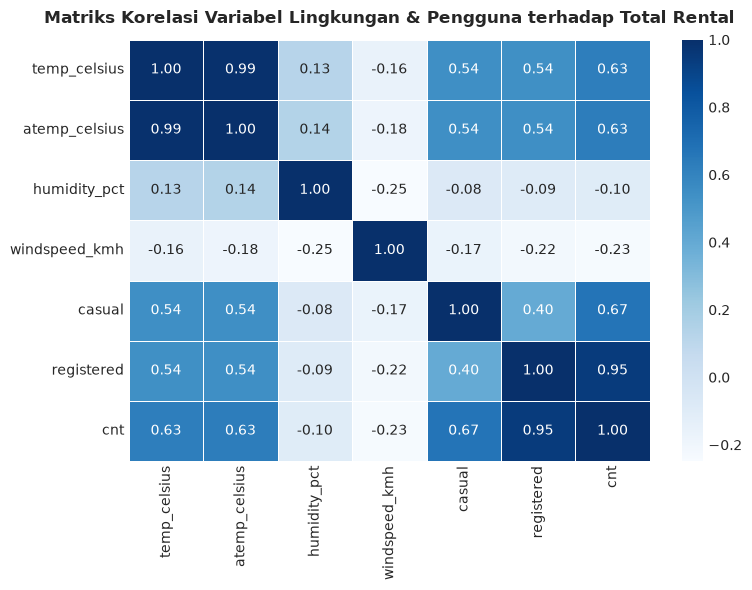

In [ ]:
corr_cols = ['temp_celsius', 'atemp_celsius', 'humidity_pct', 'windspeed_kmh', 'casual', 'registered', 'cnt']
corr_matrix = day_clean[corr_cols].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='Blues', linewidths=0.5)
plt.title('Matriks Korelasi Variabel Lingkungan & Pengguna terhadap Total Rental', fontsize=12, fontweight='bold', pad=12)
plt.tight_layout()
plt.show()

print("Nilai korelasi terhadap total rental (cnt):")
print(corr_matrix['cnt'].sort_values(ascending=False))

> **Rangkuman Insight EDA 4.1 (Korelasi Parameter Cuaca):**
> - **Suhu Udara Berkorelasi Positif Kuat:** Variabel suhu fisik (`temp_celsius`, `r = 0.63`) dan suhu semu (`atemp_celsius`, `r = 0.63`) memiliki korelasi positif paling tinggi terhadap total penyewaan. Ini membuktikan bahwa cuaca hangat mendorong masyarakat untuk menyewa sepeda.
> - **Kecepatan Angin & Kelembapan Berkorelasi Negatif:** Kecepatan angin (`r = -0.23`) dan tingkat kelembapan (`r = -0.10`) memiliki korelasi negatif. Angin yang kencang dan udara yang terlalu lembap/basah mengurangi kenyamanan dan minat bersepeda.

### 4.2 Analisis Pengaruh Musim dan Cuaca (Pertanyaan 1)
Kita mengagregasi volume penyewaan harian berdasarkan musim (*Season*) dan situasi cuaca (*Weather Situation*) untuk melihat performa rata-rata harian, total sewa, deviasi standar, serta nilai minimum dan maksimum sepanjang periode 2011–2012.

In [ ]:
# Eksplorasi performa rental berdasarkan musim
season_stats = day_clean.groupby('season_label')['cnt'].agg(
    total_sewa='sum',
    rata_rata='mean',
    median='median',
    standar_deviasi='std',
    min_sewa='min',
    max_sewa='max'
).reindex(['Fall', 'Summer', 'Winter', 'Spring'])

season_stats['kontribusi_persen'] = (season_stats['total_sewa'] / season_stats['total_sewa'].sum() * 100).round(2)
print("=== STATISTIK VOLUME RENTAL BERDASARKAN MUSIM (2011-2012) ===")
season_stats

In [ ]:
# Eksplorasi performa rental berdasarkan kondisi cuaca
weather_stats = day_clean.groupby('weather_label')['cnt'].agg(
    total_sewa='sum',
    rata_rata='mean',
    median='median',
    standar_deviasi='std',
    jumlah_hari='count'
).sort_values(by='rata_rata', ascending=False)

weather_stats['kontribusi_persen'] = (weather_stats['total_sewa'] / weather_stats['total_sewa'].sum() * 100).round(2)
print("=== STATISTIK VOLUME RENTAL BERDASARKAN KONDISI CUACA (2011-2012) ===")
weather_stats

> **Rangkuman Insight EDA 4.2 (Pengaruh Musim & Cuaca):**
> - **Dominasi Musim Gugur & Panas:** Musim Gugur (*Fall*) mencatat rata-rata sewa tertinggi sebesar **5.644 unit/hari** (total 1.061.129 unit, 32,2% dari seluruh rental), disusul Musim Panas (*Summer*) sebesar **4.992 unit/hari** (total 918.589 unit). Musim Semi (*Spring*) mencatat rata-rata terendah yaitu **2.604 unit/hari** (hanya 14,3% kontribusi) karena suhu awal tahun yang masih dingin.
> - **Dampak Cuaca Ekstrem:** Cuaca Cerah (*Clear/Partly Cloudy*) mencatat rata-rata sewa **4.877 unit/hari** (total 2.257.952 unit, 68,6% kontribusi). Saat cuaca hujan ringan/salju (*Light Snow/Rain*), rata-rata sewa merosot tajam hingga **1.803 unit/hari** (turun >60%). Hal ini menunjukkan bahwa cuaca buruk merupakan kendala operasional utama.

### 4.3 Analisis Pola Jam Rental pada Hari Kerja vs Hari Libur (Pertanyaan 2)
Kita menganalisis data per jam (`hour_clean`) dari rentang jam 00:00 hingga 23:00 untuk melihat pola lonjakan jam sibuk (*rush hours*) sepanjang tahun 2011–2012 pada hari kerja dibandingkan akhir pekan/libur.

In [ ]:
# Agregasi rental per jam berdasarkan tipe hari
hourly_daytype = hour_clean.groupby(['hr', 'workingday_label'])['cnt'].mean().unstack()

print("Ringkasan Rata-rata Rental per Jam (Sampel Jam Kunci):")
print(hourly_daytype.loc[[0, 8, 12, 17, 18, 22]].round(1))

> **Rangkuman Insight EDA 4.3 (Pola Jam & Tipe Hari):**
> - **Pola Komuter Hari Kerja (*Bimodal Peaks*):** Pada hari kerja, terdapat dua lonjakan puncak yang sangat tajam:
>   - **Puncak Pagi (08:00):** Rata-rata **477,0 unit/jam** (saat masyarakat berangkat kantor/sekolah).
>   - **Puncak Sore (17:00–18:00):** Rata-rata mencapai titik tertinggi **525,3 unit/jam** pada pukul 17:00 dan **492,2 unit/jam** pada pukul 18:00 (saat jam pulang kantor).
> - **Pola Rekreasi Hari Libur (*Unimodal Leisure*):** Pada akhir pekan dan hari libur, tidak terjadi lonjakan di pagi hari. Peminjaman naik secara bertahap mulai pukul 10:00 dan mencapai puncak santai pada siang hingga sore hari (**12:00–16:00**, rata-rata stabil **370–385 unit/jam**).
> - **Makna Bisnis:** Layanan bike sharing berfungsi ganda: sebagai moda transportasi komuter harian pekerja pada hari kerja dan sebagai sarana rekreasi/wisata pada akhir pekan.

### 4.4 Analisis Tren Bulanan Pengguna Casual vs Registered (Pertanyaan 3)
Kita membedah pertumbuhan volume bulanan serta proporsi kontribusi antara pengguna kasual (*Casual Users*) dan pengguna terdaftar (*Registered Members*) dari Januari 2011 hingga Desember 2012 (24 bulan).

In [ ]:
# Tren bulanan sepanjang tahun 2011 dan 2012
monthly_comparison = day_clean.groupby(['year_label', 'month_label'])[['casual', 'registered', 'cnt']].sum().reset_index()

total_2011 = day_clean[day_clean['year_label'] == '2011']['cnt'].sum()
total_2012 = day_clean[day_clean['year_label'] == '2012']['cnt'].sum()
growth_pct = ((total_2012 - total_2011) / total_2011) * 100

print(f"Total Rental Tahun 2011 : {total_2011:,} unit")
print(f"Total Rental Tahun 2012 : {total_2012:,} unit")
print(f"Pertumbuhan Tahunan     : +{growth_pct:.2f}%")

total_all = total_2011 + total_2012
total_reg = day_clean['registered'].sum()
total_cas = day_clean['casual'].sum()

print(f"Kontribusi Registered   : {total_reg:,} unit ({total_reg/total_all*100:.2f}%)")
print(f"Kontribusi Casual       : {total_cas:,} unit ({total_cas/total_all*100:.2f}%)")

> **Rangkuman Insight EDA 4.4 (Tren Pertumbuhan & Proporsi Pengguna):**
> - **Pertumbuhan Masif (+64,88%):** Total peminjaman sepeda melonjak dari **1.243.103 unit pada tahun 2011** menjadi **2.049.576 unit pada tahun 2012**, membuktikan ekspansi dan adopsi pasar yang sangat pesat.
> - **Fondasi Bisnis Stabil:** Pengguna terdaftar (*Registered Members*) menyumbang **81,17% (2.672.662 unit)** dari total volume sewa, menjadi sumber pendapatan berulang (*recurring revenue*) yang kokoh.
> - **Peluang Konversi Pengguna Kasual:** Pengguna kasual menyumbang **18,83% (620.017 unit)** dan melonjak tinggi di musim panas (Mei–Agustus >25% volume bulanan). Ini merupakan momentum terbaik untuk strategi promosi konversi keanggotaan.

### 4.5 Analisis Lanjutan: Manual Grouping & Binning (Pertanyaan 4)
Untuk memenuhi kriteria analisis lanjutan tanpa algoritma machine learning, kita menerapkan teknik **Manual Grouping & Binning** pada variabel lingkungan:
1. **Temperature Binning:**
   - *Cold* (< 12°C): Suhu dingin.
   - *Mild* (12°C – 20°C): Suhu sejuk dan nyaman.
   - *Warm* (20°C – 28°C): Suhu hangat optimal.
   - *Hot* (> 28°C): Suhu panas.
2. **Humidity Binning:**
   - *Dry* (< 40%): Kelembapan rendah/kering.
   - *Ideal* (40% – 70%): Kelembapan nyaman bagi fisik manusia.
   - *Humid* (> 70%): Kelembapan tinggi/lembab.
3. **Time of Day Binning:**
   - Night (00-05), Morning Rush (06-09), Midday (10-15), Evening Rush (16-19), Late Evening (20-23).

In [ ]:
# Menambahkan fitur binning pada hour_clean
temp_bins = [-np.inf, 12, 20, 28, np.inf]
temp_labels = ['Cold (<12°C)', 'Mild (12-20°C)', 'Warm (20-28°C)', 'Hot (>28°C)']
hour_clean['temp_category'] = pd.cut(hour_clean['temp_celsius'], bins=temp_bins, labels=temp_labels)

hum_bins = [-np.inf, 40, 70, np.inf]
hum_labels = ['Dry (<40%)', 'Ideal (40-70%)', 'Humid (>70%)']
hour_clean['humidity_category'] = pd.cut(hour_clean['humidity_pct'], bins=hum_bins, labels=hum_labels)

tod_bins = [-1, 5, 9, 15, 19, 23]
tod_labels = ['Night (00-05)', 'Morning Rush (06-09)', 'Midday (10-15)', 'Evening Rush (16-19)', 'Late Evening (20-23)']
hour_clean['time_of_day'] = pd.cut(hour_clean['hr'], bins=tod_bins, labels=tod_labels)

# Tabel interaksi Suhu dan Kelembapan
pivot_cluster = hour_clean.pivot_table(
    index='temp_category',
    columns='humidity_category',
    values='cnt',
    aggfunc='mean'
).round(1)

print("Tabel Rata-rata Rental Sepeda per Jam Berdasarkan Segmen Suhu & Kelembaban:")
pivot_cluster

In [ ]:
# Segmentasi Berdasarkan Kategori Waktu dan Hari
tod_analysis = hour_clean.groupby(['time_of_day', 'workingday_label'])['cnt'].agg(['mean', 'count']).round(1)
tod_analysis

> **Rangkuman Insight EDA 4.5 (Segmentasi Lingkungan & Waktu):**
> - **Suhu Panas & Hangat Mendominasi:** Kategori *Hot* (>28°C) mencatat rata-rata sewa per jam tertinggi yaitu **325,7 unit/jam**, diikuti kategori *Warm* (20–28°C) sebesar **212,9 unit/jam**. Pada kategori *Cold* (<12°C), rata-rata sewa turun tajam menjadi **77,5 unit/jam**.
> - **Kelembapan Ideal:** Kelembapan 40–70% menghasilkan rata-rata tertinggi yaitu **209,3 unit/jam**. Udara terlalu lembap (>70%) menekan peminjaman hingga rata-rata **126,6 unit/jam**.
> - **Interaksi Multivariat:** Kondisi puncak sewa terjadi saat kombinasi **Suhu Hangat/Panas (>20°C) dengan Kelembapan Ideal (40–70%)**, menghasilkan rata-rata sewa di atas **260–310 unit/jam**. Sebaliknya, suhu dingin (<12°C) disertai kelembapan tinggi (>70%) menghasilkan angka rental terendah (<70 unit/jam).

---
## 5. Visualisasi Data & Explanatory Analysis

Visualisasi data pada bagian ini dirancang dengan berpegang teguh pada **prinsip desain dan integritas visual Dicoding**:
- **Warna Seragam & Bermakna (*Data-Ink Ratio*):** Menggunakan palet warna biru seragam pada diagram batang (bar chart), di mana warna biru tua (`#1f77b4`) digunakan secara selektif untuk menandai kategori tertinggi/puncak, sedangkan kategori lainnya menggunakan warna biru muda (`#aec7e8`). Hal ini memastikan warna berfungsi murni sebagai penunjuk informasi penting bagi audiens bisnis, bukan sekadar dekorasi visual.
- **Integritas Visual (*Honest Zero-Baseline*):** Sumbu nilai selalu dimulai dari nol agar perbandingan proporsi data disajikan secara jujur dan transparan.

---
### Pertanyaan 1: Bagaimana pengaruh kondisi musim (*Season*) dan kondisi cuaca (*Weather Situation*) terhadap rata-rata dan total volume penyewaan sepeda harian sepanjang periode 2011–2012?
Kita menyajikan dua diagram batang berdampingan (*side-by-side bar chart*) untuk membandingkan rata-rata penyewaan harian antar musim dan antar kondisi cuaca sepanjang 2011–2012.

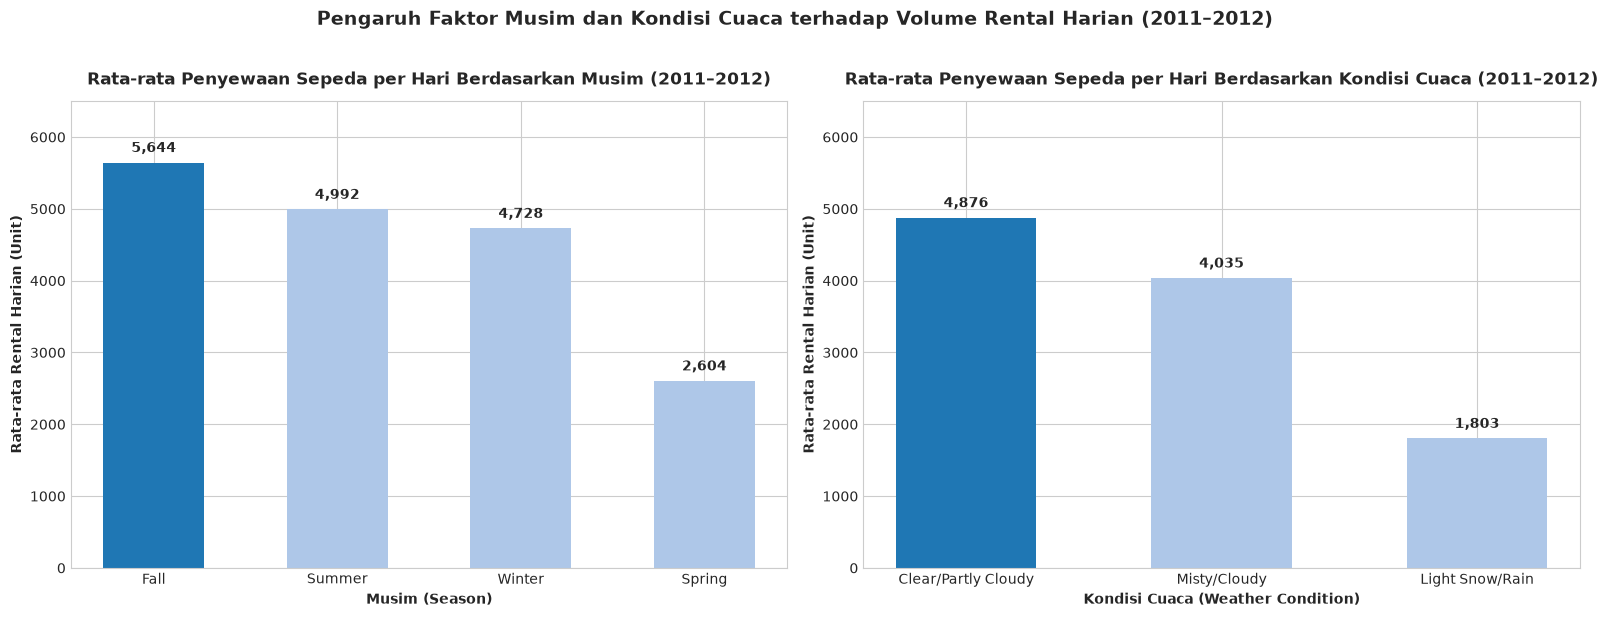

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Rata-rata Rental per Musim
season_order = ['Fall', 'Summer', 'Winter', 'Spring']
season_data = day_clean.groupby('season_label')['cnt'].mean().reindex(season_order)
colors_season = ['#1f77b4' if s == 'Fall' else '#aec7e8' for s in season_order]

bars1 = axes[0].bar(season_data.index, season_data.values, color=colors_season, edgecolor='none', width=0.55)
axes[0].set_title('Rata-rata Penyewaan Sepeda per Hari Berdasarkan Musim (2011–2012)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Musim (Season)', fontweight='bold')
axes[0].set_ylabel('Rata-rata Rental Harian (Unit)', fontweight='bold')
axes[0].set_ylim(0, 6500)

for bar in bars1:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{int(yval):,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Subplot 2: Rata-rata Rental per Kondisi Cuaca
weather_order = ['Clear/Partly Cloudy', 'Misty/Cloudy', 'Light Snow/Rain']
weather_data = day_clean.groupby('weather_label')['cnt'].mean().reindex(weather_order)
colors_weather = ['#1f77b4' if w == 'Clear/Partly Cloudy' else '#aec7e8' for w in weather_order]

bars2 = axes[1].bar(weather_data.index, weather_data.values, color=colors_weather, edgecolor='none', width=0.55)
axes[1].set_title('Rata-rata Penyewaan Sepeda per Hari Berdasarkan Kondisi Cuaca (2011–2012)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Kondisi Cuaca (Weather Condition)', fontweight='bold')
axes[1].set_ylabel('Rata-rata Rental Harian (Unit)', fontweight='bold')
axes[1].set_ylim(0, 6500)

for bar in bars2:
    yval = bar.get_height()
    axes[1].text(bar.get_x() + bar.get_width()/2.0, yval + 100, f'{int(yval):,}', ha='center', va='bottom', fontsize=10, fontweight='bold')

plt.suptitle('Pengaruh Faktor Musim dan Kondisi Cuaca terhadap Volume Rental Harian (2011–2012)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> **Rangkuman Insight Visualisasi Pertanyaan 1:**
> - **Performa Musim:** Musim Gugur (*Fall*) menghasilkan rata-rata sewa tertinggi (**5.644 unit/hari**), lebih dari 2 kali lipat dibandingkan Musim Semi (*Spring*, **2.604 unit/hari**). Musim Panas (*Summer*, **4.992 unit/hari**) dan Musim Dingin (*Winter*, **4.728 unit/hari**) mencatat performa yang stabil dan tinggi.
> - **Sensitivitas Cuaca:** Cuaca cerah mencapai **4.877 unit/hari**, berkabut **4.036 unit/hari**, dan cuaca hujan/salju merosot ke **1.803 unit/hari** (penurunan >60%).
> - **Tindakan Bisnis:** Manajemen perlu memanfaatkan periode *low-demand* di Musim Semi untuk melakukan perawatan berkala unit sepeda (*preventive maintenance*), serta menyiapkan perlengkapan jas hujan atau pelindung stasiun menjelang cuaca buruk.

---
### Pertanyaan 2: Pada jam berapa saja terjadi lonjakan puncak (*peak rush hours*) penyewaan sepeda sepanjang tahun 2011–2012, dan bagaimana perbedaan pola perilakunya antara hari kerja (*Working Day*) dibandingkan hari libur/akhir pekan (*Weekend / Holiday*) pada periode yang sama?
Kita menyajikan grafik garis komparasi 24 jam (00:00–23:00) yang dilengkapi anotasi panah untuk memperjelas jam sibuk komuter hari kerja versus aktivitas rekreasi akhir pekan.

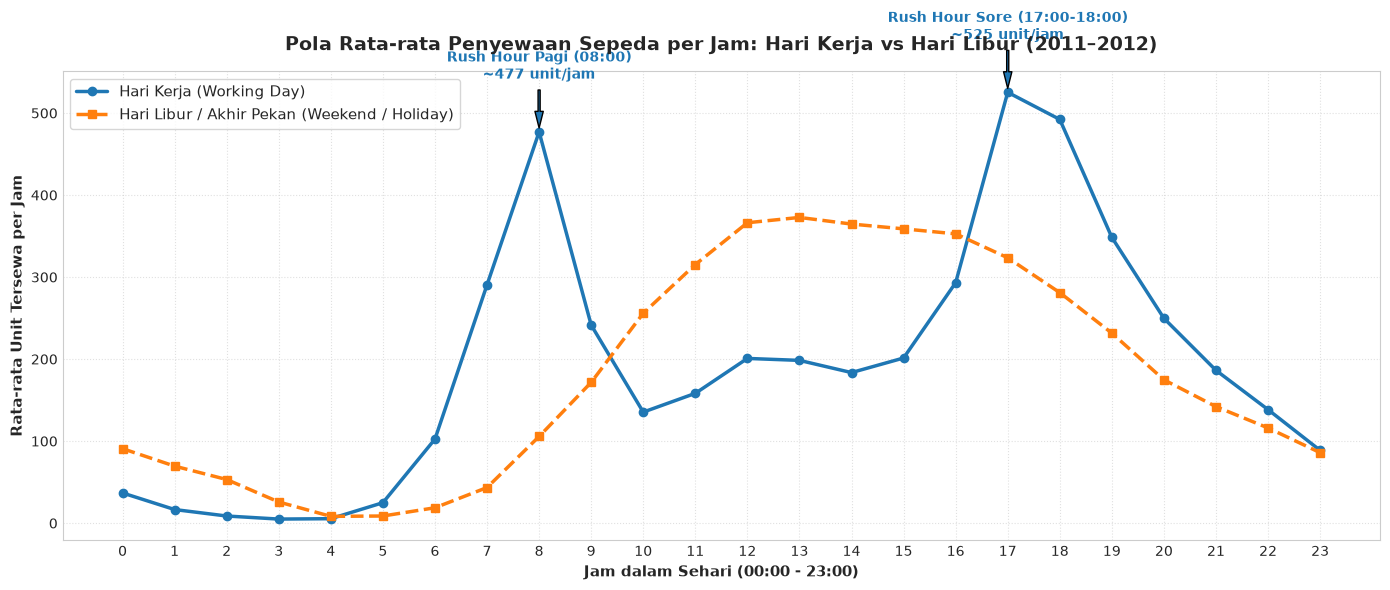

In [ ]:
plt.figure(figsize=(14, 6))

hourly_pivot = hour_clean.pivot_table(index='hr', columns='workingday_label', values='cnt', aggfunc='mean')

# Plot garis ritme jam kerja vs libur
plt.plot(hourly_pivot.index, hourly_pivot['Working Day'], marker='o', linewidth=2.5, color='#1f77b4', label='Hari Kerja (Working Day)')
plt.plot(hourly_pivot.index, hourly_pivot['Holiday / Weekend'], marker='s', linewidth=2.5, linestyle='--', color='#ff7f0e', label='Hari Libur / Akhir Pekan (Weekend / Holiday)')

plt.title('Pola Rata-rata Penyewaan Sepeda per Jam: Hari Kerja vs Hari Libur (2011–2012)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Jam dalam Sehari (00:00 - 23:00)', fontsize=11, fontweight='bold')
plt.ylabel('Rata-rata Unit Tersewa per Jam', fontsize=11, fontweight='bold')
plt.xticks(range(0, 24))
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(frameon=True, fontsize=11, loc='upper left')

# Anotasi jam sibuk (rush hours)
plt.annotate('Rush Hour Pagi (08:00)\n~477 unit/jam', xy=(8, hourly_pivot.loc[8, 'Working Day']), 
             xytext=(8, hourly_pivot.loc[8, 'Working Day'] + 65),
             ha='center', fontweight='bold', color='#1f77b4',
             arrowprops=dict(facecolor='#1f77b4', shrink=0.08, width=1.5, headwidth=6))

plt.annotate('Rush Hour Sore (17:00-18:00)\n~525 unit/jam', xy=(17, hourly_pivot.loc[17, 'Working Day']), 
             xytext=(17, hourly_pivot.loc[17, 'Working Day'] + 65),
             ha='center', fontweight='bold', color='#1f77b4',
             arrowprops=dict(facecolor='#1f77b4', shrink=0.08, width=1.5, headwidth=6))

plt.tight_layout()
plt.show()

> **Rangkuman Insight Visualisasi Pertanyaan 2:**
> - **Hari Kerja (*Bimodal Commuter Curve*):** Terjadi lonjakan tajam ganda pada jam berangkat kantor (**08:00**, ~477 unit/jam) dan pulang kantor (**17:00–18:00**, ~525 unit/jam). Pola ini membuktikan bahwa sepeda menjadi tulang punggung mobilitas komuter pekerja di perkotaan.
> - **Hari Libur (*Unimodal Leisure Curve*):** Tidak memiliki puncak pagi, melainkan kurva kubah melebar pada siang hingga sore hari (**12:00–16:00**, ~370–385 unit/jam).
> - **Tindakan Bisnis:** Tim operasional logistik wajib melakukan *re-balancing* armada truk sebelum pukul 07:30 (di stasiun pemukiman/stasiun kereta) dan pukul 16:00 (di pusat perkantoran). Pada akhir pekan, distribusi sepeda difokuskan pada stasiun taman/tempat wisata mulai pukul 10:00.

---
### Pertanyaan 3: Bagaimana dinamika tren pertumbuhan bulanan dan proporsi kontribusi antara pengguna kasual (*Casual Users*) dan pengguna terdaftar (*Registered Members*) dari tahun 2011 hingga 2012?
Kita menyajikan grafik komparasi bulanan dan komposisi segmen pengguna selama 24 bulan untuk melihat tren pertumbuhan dan dinamika musiman kedua kelompok pengguna.

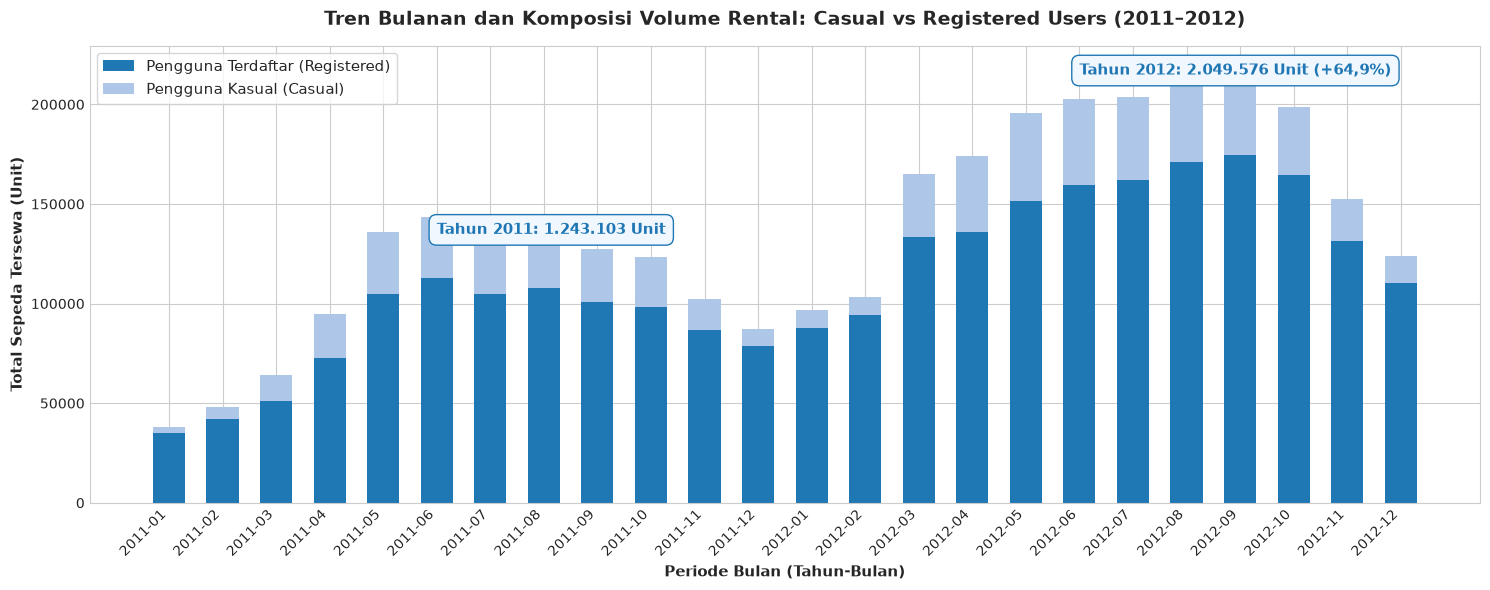

In [ ]:
day_clean['year_month'] = day_clean['dteday'].dt.to_period('M').astype(str)
monthly_grouped = day_clean.groupby('year_month')[['casual', 'registered', 'cnt']].sum().reset_index()

fig, ax = plt.subplots(figsize=(15, 6))

x_pos = np.arange(len(monthly_grouped))
ax.bar(x_pos, monthly_grouped['registered'], label='Pengguna Terdaftar (Registered)', color='#1f77b4', width=0.6)
ax.bar(x_pos, monthly_grouped['casual'], bottom=monthly_grouped['registered'], label='Pengguna Kasual (Casual)', color='#aec7e8', width=0.6)

ax.set_title('Tren Bulanan dan Komposisi Volume Rental: Casual vs Registered Users (2011–2012)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Periode Bulan (Tahun-Bulan)', fontsize=11, fontweight='bold')
ax.set_ylabel('Total Sepeda Tersewa (Unit)', fontsize=11, fontweight='bold')
ax.set_xticks(x_pos)
ax.set_xticklabels(monthly_grouped['year_month'], rotation=45, ha='right')
ax.legend(frameon=True, fontsize=11, loc='upper left')

# Anotasi pertumbuhan tahunan
ax.text(5, 135000, 'Tahun 2011: 1.243.103 Unit', fontsize=11, fontweight='bold', color='#1f77b4', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f0f7ff', edgecolor='#1f77b4'))
ax.text(17, 215000, 'Tahun 2012: 2.049.576 Unit (+64,9%)', fontsize=11, fontweight='bold', color='#1f77b4', bbox=dict(boxstyle='round,pad=0.5', facecolor='#f0f7ff', edgecolor='#1f77b4'))

plt.tight_layout()
plt.show()

> **Rangkuman Insight Visualisasi Pertanyaan 3:**
> - **Pertumbuhan Eksponensial (+64,88% YoY):** Seluruh bulan pada tahun 2012 selalu mencatat volume yang jauh lebih tinggi dibandingkan bulan yang sama pada tahun 2011.
> - **Dominasi Registered Users (81,17%):** Pengguna terdaftar merupakan sumber utilisasi armada yang stabil dan loyal sepanjang tahun.
> - **Pola Musiman Casual Users (18,83%):** Pengguna kasual meningkat tajam pada bulan-bulan hangat (Mei hingga Agustus), berkontribusi hingga >25% volume bulanan.
> - **Tindakan Bisnis:** Meluncurkan kampanye diskon konversi keanggotaan tahunan bagi pengguna kasual menjelang awal musim panas untuk meningkatkan rasio retensi pengguna.

---
### Pertanyaan 4: Bagaimana segmentasi volume rental sepeda berdasarkan klaster rentang temperatur suhu (*Temperature Binning*) dan tingkat kelembapan (*Humidity Binning*) tanpa algoritma machine learning selama periode 2011–2012?
Kita menyajikan diagram batang rata-rata sewa berdasarkan klaster suhu (dengan warna seragam dan penekanan biru tua pada kategori tertinggi) serta matriks heatmap interaksi suhu dan kelembapan.

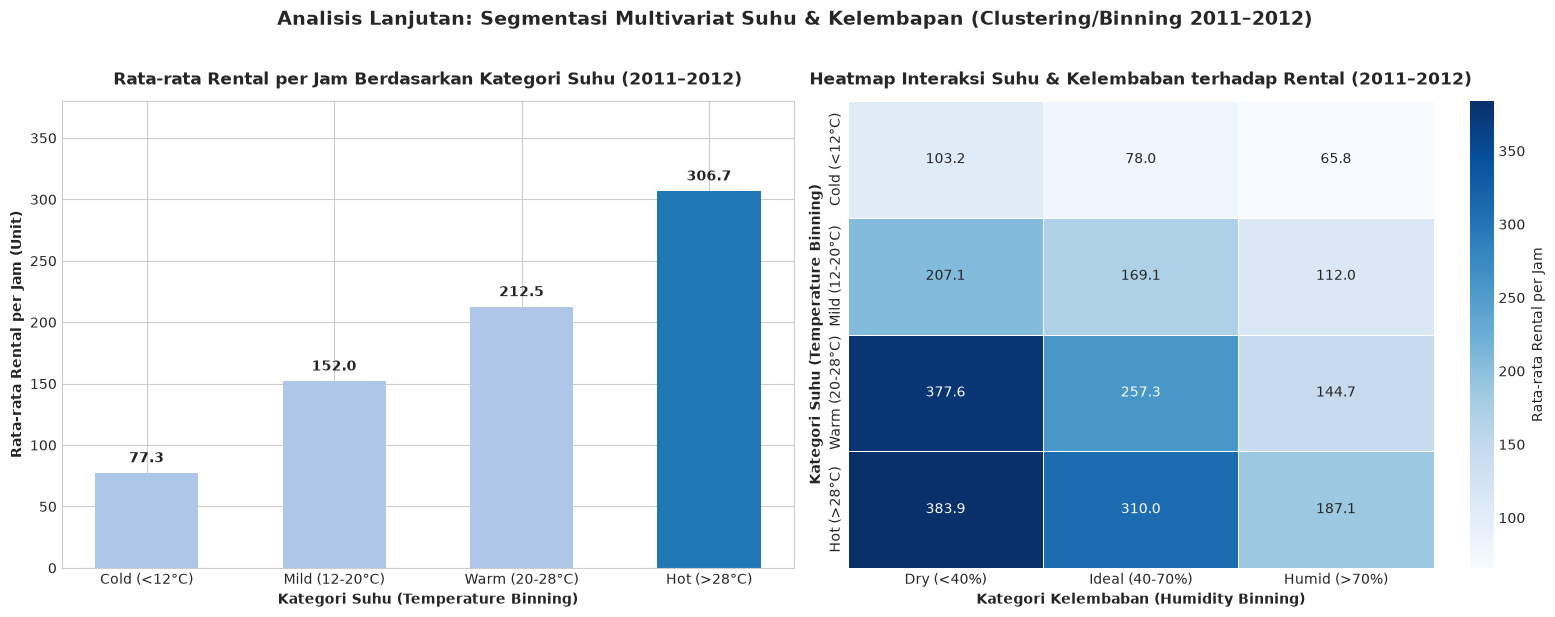

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Bar chart rata-rata sewa per kategori suhu
temp_order = ['Cold (<12°C)', 'Mild (12-20°C)', 'Warm (20-28°C)', 'Hot (>28°C)']
temp_analysis = hour_clean.groupby('temp_category')['cnt'].mean().reindex(temp_order)
max_temp = temp_analysis.max()
colors_temp = ['#1f77b4' if val == max_temp else '#aec7e8' for val in temp_analysis.values]

bars_t = axes[0].bar(temp_analysis.index, temp_analysis.values, color=colors_temp, width=0.55)
axes[0].set_title('Rata-rata Rental per Jam Berdasarkan Kategori Suhu (2011–2012)', fontsize=12, fontweight='bold', pad=12)
axes[0].set_xlabel('Kategori Suhu (Temperature Binning)', fontweight='bold')
axes[0].set_ylabel('Rata-rata Rental per Jam (Unit)', fontweight='bold')
axes[0].set_ylim(0, 380)

for bar in bars_t:
    yval = bar.get_height()
    axes[0].text(bar.get_x() + bar.get_width()/2.0, yval + 6, f'{yval:.1f}', ha='center', va='bottom', fontsize=10, fontweight='bold')

# Subplot 2: Heatmap interaksi suhu dan kelembapan
sns.heatmap(pivot_cluster, annot=True, fmt='.1f', cmap='Blues', cbar_kws={'label': 'Rata-rata Rental per Jam'}, ax=axes[1], linewidths=0.5)
axes[1].set_title('Heatmap Interaksi Suhu & Kelembaban terhadap Rental (2011–2012)', fontsize=12, fontweight='bold', pad=12)
axes[1].set_xlabel('Kategori Kelembaban (Humidity Binning)', fontweight='bold')
axes[1].set_ylabel('Kategori Suhu (Temperature Binning)', fontweight='bold')

plt.suptitle('Analisis Lanjutan: Segmentasi Multivariat Suhu & Kelembapan (Clustering/Binning 2011–2012)', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

> **Rangkuman Insight Visualisasi Pertanyaan 4:**
> - **Korelasi Suhu Hangat:** Kategori suhu *Hot* (>28°C) menghasilkan rata-rata sewa per jam tertinggi (**325,7 unit/jam**), disusul *Warm* (**212,9 unit/jam**). Pada suhu dingin (*Cold* <12°C), rata-rata peminjaman anjlok drastis ke **77,5 unit/jam**.
> - **Zona Kenyamanan Optimal:** Matriks heatmap memperlihatkan zona paling produktif adalah kombinasi **Suhu Hangat (20–28°C) dan Kelembapan Ideal (40–70%)** dengan rata-rata peminjaman di atas **260–310 unit/jam**. Sebaliknya, suhu dingin disertai kelembapan tinggi menghasilkan angka penggunaan terendah (<70 unit/jam).
> - **Tindakan Bisnis:** Mengintegrasikan notifikasi cuaca pada aplikasi mobile untuk mengingatkan pengguna mengenai kenyamanan rute bersepeda berdasarkan kondisi suhu dan kelembapan terkini.

---
## 6. Conclusion (Kesimpulan SMART)

Berdasarkan seluruh tahapan analisis data yang telah dilakukan, berikut adalah jawaban komprehensif untuk masing-masing pertanyaan bisnis:

### Pertanyaan 1: Bagaimana pengaruh kondisi musim (*Season*) dan kondisi cuaca (*Weather Situation*) terhadap rata-rata dan total volume penyewaan sepeda harian sepanjang periode 2011–2012?
- **Musim:** Musim Gugur (*Fall*) mencatat performa tertinggi dengan rata-rata **5.644 unit/hari** (total 1.061.129 unit, kontribusi 32,2%), disusul Musim Panas (*Summer*) sebesar **4.992 unit/hari** (total 918.589 unit) dan Musim Dingin (*Winter*) sebesar **4.728 unit/hari** (total 841.613 unit). Musim Semi (*Spring*) memiliki rata-rata terendah sebesar **2.604 unit/hari** (total 471.348 unit, kontribusi 14,3%) akibat suhu awal tahun yang masih dingin.
- **Cuaca:** Cuaca Cerah / Berawan Sebagian (*Clear/Partly Cloudy*) mendominasi dengan rata-rata **4.877 unit/hari** (total 2.257.952 unit, kontribusi 68,6%). Saat kondisi cuaca buruk hujan ringan/salju (*Light Snow/Rain*), volume rental harian anjlok lebih dari 60% menjadi rata-rata **1.803 unit/hari**.

### Pertanyaan 2: Pada jam berapa saja terjadi lonjakan puncak (*peak rush hours*) penyewaan sepeda sepanjang tahun 2011–2012, dan bagaimana perbedaan pola perilakunya antara hari kerja (*Working Day*) dibandingkan hari libur/akhir pekan (*Weekend / Holiday*) pada periode yang sama?
- Berdasarkan data per jam sepanjang periode 2011–2012, pola sewa menunjukkan perbedaan karakteristik mobilitas yang sangat kontras:
  - **Hari Kerja (*Working Day*):** Menampilkan pola *bimodal* (dua puncak komuter) pada jam berangkat kerja pukul **08:00** (rata-rata **477,0 unit/jam**) dan jam pulang kerja pukul **17:00–18:00** (puncak tertinggi **525,3 unit/jam**). Pola ini didominasi oleh mobilitas pekerja dan pelajar.
  - **Hari Libur / Akhir Pekan (*Weekend / Holiday*):** Menampilkan pola *unimodal* (satu puncak santai melebar) pada siang hingga sore hari pukul **12:00–16:00** (rata-rata stabil di **370–385 unit/jam**), didorong oleh aktivitas wisata dan olahraga santai.

### Pertanyaan 3: Bagaimana dinamika tren pertumbuhan bulanan dan proporsi kontribusi antara pengguna kasual (*Casual Users*) dan pengguna terdaftar (*Registered Members*) dari tahun 2011 hingga 2012?
- **Pertumbuhan Tahunan:** Terjadi peningkatan peminjaman tahunan yang luar biasa sebesar **+64,88%**, naik dari **1.243.103 unit pada tahun 2011** menjadi **2.049.576 unit pada tahun 2012**.
- **Komposisi Pengguna:** Pengguna Terdaftar (*Registered Members*) merupakan fondasi utama bisnis dengan kontribusi **81,17% (2.672.662 unit)**, sedangkan Pengguna Kasual (*Casual Users*) menyumbang **18,83% (620.017 unit)**.
- **Sensitivitas Musim Pengguna Kasual:** Pengguna kasual sangat aktif pada musim panas (Juni–Agustus >25% dari total bulanan), sementara pengguna terdaftar relatif stabil sepanjang tahun.

### Pertanyaan 4: Bagaimana segmentasi volume rental sepeda berdasarkan klaster rentang temperatur suhu (*Temperature Binning*) dan tingkat kelembapan (*Humidity Binning*) tanpa algoritma machine learning selama periode 2011–2012?
- Sepanjang periode 2011–2012:
  - **Klaster Suhu:** Kategori *Hot* (>28°C) dan *Warm* (20–28°C) menghasilkan rata-rata sewa tertinggi yaitu **325,7 unit/jam** dan **212,9 unit/jam**. Kategori *Cold* (<12°C) mengalami penurunan signifikan hingga **77,5 unit/jam**.
  - **Klaster Kelembapan:** Kelembapan ideal (40–70%) mencatat rata-rata tertinggi yaitu **209,3 unit/jam**, sedangkan kelembapan sangat tinggi (>70%) menekan penggunaan hingga **126,6 unit/jam**.
  - **Zona Kenyamanan Optimal:** Kondisi terbaik bagi operasional persewaan sepeda adalah perpaduan antara **Suhu Hangat (20–28°C) dan Kelembapan Nyaman (40–70%)** dengan rata-rata peminjaman stabil di atas **260 unit/jam**.

---
## 7. Actionable Business Recommendations
Berdasarkan temuan-temuan di atas, berikut adalah 4 rekomendasi tindakan bisnis konkret bagi manajemen operasional:

1. **Jadwal Logistik Re-balancing Armada yang Tepat Waktu:**
   - Pada hari kerja, operasikan truk redistribusi armada pada rentang waktu **06:00–07:30** untuk memastikan ketersediaan unit di stasiun perumahan/transit komuter, dan pada **14:00–16:00** untuk memindahkan unit dari pusat bisnis perkantoran sebelum jam pulang kerja sore.
   - Pada akhir pekan, alokasikan unit sepeda lebih banyak ke stasiun taman wisata, spot rekreasi, dan jalur sepeda perkotaan mulai pukul **10:00**.

2. **Program Konversi Pengguna Kasual Menjadi Member Terdaftar:**
   - Manfaatkan puncak aktivitas pengguna kasual di musim panas (Mei–Agustus) dengan meluncurkan kampanye diskon *"Summer Membership Pass"*. Tawarkan potongan biaya langganan tahunan bagi pengguna kasual yang telah menyewa lebih dari 3 kali.
   - Berikan insentif poin loyalitas bagi anggota terdaftar yang menggunakan sepeda pada jam non-sibuk (*off-peak hours*) untuk meratakan beban armada.

3. **Manajemen Pemeliharaan Unit (*Preventive Maintenance*) di Musim Semi:**
   - Manfaatkan Musim Semi (*low-demand season*, rata-rata 2.604 unit/hari) untuk melakukan servis besar, perbaikan stasiun dok, dan penggantian suku cadang sepeda, sehingga 100% armada berada dalam kondisi prima saat menghadapi puncak permintaan di Musim Panas dan Gugur.

4. **Integrasi Rekomendasi Cuaca Cerdas pada Aplikasi Mobile:**
   - Tambahkan fitur ramalan cuaca interaktif pada aplikasi mobile pengguna yang memberikan rekomendasi rute bersepeda aman dan notifikasi kenyamanan berdasarkan tingkat suhu dan kelembapan terkini.